In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
print("Libraries loaded")

Libraries loaded


In [2]:
df = pd.read_csv("penguins.csv")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
print("First 5 records:")
display(df.head())
print("Last 5 records:")
display(df.tail())

First 5 records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Last 5 records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


In [4]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)

Rows: 344 | Columns: 8

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Data types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object


### Task 1 Interpretation
The dataset has 344 rows and 8 columns. It contains physical measurements of penguins from the Palmer Archipelago. There are 3 categorical columns (species, island, sex) and 5 numerical columns (bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, year). The `describe(include='object')` output shows 3 species, 3 islands and 2 sex values, with Adelie (152 rows), Biscoe (168 rows) and male (168 rows) being the most frequent. The `sex` column has a count of 333 against 344 rows, which indicates missing values that must be handled in Task 2.

### Task 2 Interpretation
Before handling, the dataset had 19 missing values in total. The `sex` column had 11 missing values (3.2%), and each of bill_length_mm, bill_depth_mm, flipper_length_mm and body_mass_g had 2 missing values (0.58%). These percentages are very small, so filling the values is better than deleting rows, because deleting would waste the other valid measurements of those penguins.

For the numerical columns I used the median instead of the mean. The median is not affected by extreme values, so it gives a safer central value if some measurements are unusually large or small. For the categorical column `sex` I used the mode (male), because a mean cannot be calculated for text categories, so the most frequent category is the natural replacement.

After filling, the before/after table shows 0 missing values in every column.

In [5]:
print("Numerical columns:")
display(df.describe())
print("Categorical columns:")
display(df.describe(include='object'))

Numerical columns:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


Categorical columns:


C:\Users\HB LAPTOP\AppData\Local\Temp\ipykernel_8568\1737554440.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


In [6]:
print("Numerical columns:")
display(df.describe())
print("Categorical columns:")
display(df.select_dtypes(exclude='number').describe())

Numerical columns:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


Categorical columns:


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


### Task 4 Interpretation
The categorical columns are species, island and sex. I checked each column with `value_counts()` and `unique()`, and also looked for stray spaces and mixed capitalization. The categories were already consistent: species has 3 values (Adelie, Chinstrap, Gentoo), island has 3 values (Biscoe, Dream, Torgersen) and sex has 2 values (Male, Female), with no variants such as "male"/"MALE" and no extra spaces. I still applied `str.strip()` and `str.title()` as a safe standardization step, and the before/after lists are identical, which confirms the data was already clean. No values were changed or removed.

In [7]:
print("Numerical columns:")
display(df.describe())
print("Categorical columns:")
display(df.describe(include='object'))

Numerical columns:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


Categorical columns:


C:\Users\HB LAPTOP\AppData\Local\Temp\ipykernel_8568\1737554440.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


### Task 5 Interpretation
I checked bill_length_mm, bill_depth_mm, flipper_length_mm and body_mass_g using boxplots and the IQR method (lower bound = Q1 - 1.5*IQR, upper bound = Q3 + 1.5*IQR). The IQR table shows 0 values outside the bounds for all four columns, and the boxplots confirm that no points lie beyond the whiskers. Therefore I decided to retain all rows and not remove or cap anything.

Even if some extreme values had appeared, I would have investigated them before removing them. Penguin measurements vary naturally between species (for example, Gentoo penguins are much heavier than Adelie penguins), so a value that looks extreme for the whole dataset can be completely normal for one species. Deleting such values would remove real biological variation, not errors.

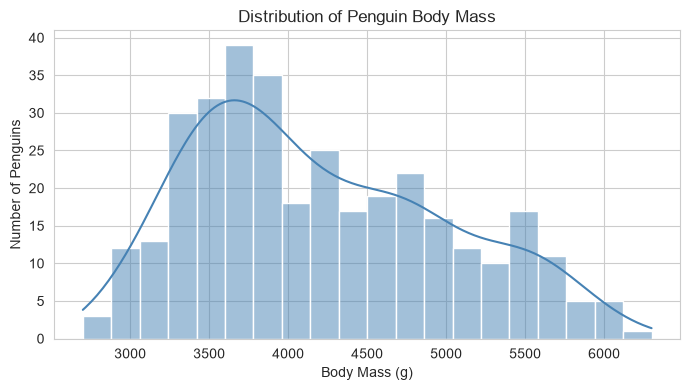

In [8]:
plt.figure(figsize=(7, 4))
sns.histplot(df["body_mass_g"], bins=20, kde=True, color="steelblue")
plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (g)")
plt.ylabel("Number of Penguins")
plt.tight_layout()
plt.savefig("hist_body_mass.png", dpi=150)
plt.show()

In [9]:
df["bill_ratio"] = df["bill_length_mm"] / df["bill_depth_mm"]
display(df[["bill_length_mm", "bill_depth_mm", "bill_ratio"]].head())

,bill_length_mm,bill_depth_mm,bill_ratio
0,39.1,18.7,2.090909
1,39.5,17.4,2.270115
2,40.3,18.0,2.238889
3,NaN,NaN,NaN
4,36.7,19.3,1.901554


In [10]:
display(df.groupby("species")["bill_ratio"].describe().round(2))

,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Adelie,151.0,2.12,0.15,1.64,2.01,2.14,2.24,2.45
Chinstrap,68.0,2.65,0.15,2.35,2.56,2.66,2.73,3.26
Gentoo,123.0,3.18,0.17,2.57,3.07,3.17,3.29,3.61


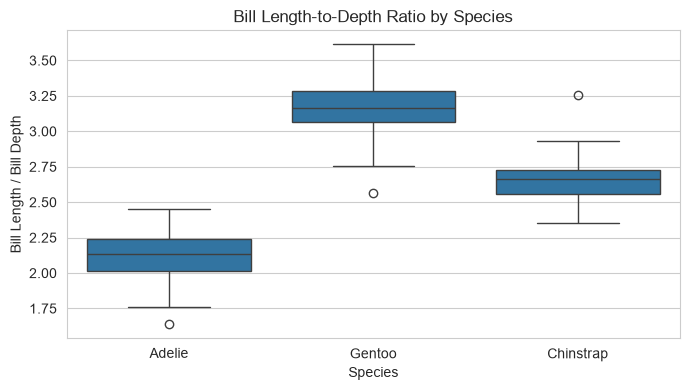

In [11]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="species", y="bill_ratio")
plt.title("Bill Length-to-Depth Ratio by Species")
plt.xlabel("Species")
plt.ylabel("Bill Length / Bill Depth")
plt.tight_layout()
plt.savefig("box_bill_ratio.png", dpi=150)
plt.show()

### Task 7 Interpretation
I created a new feature called `bill_ratio`, which is bill_length_mm divided by bill_depth_mm. It describes the shape of the bill (long and thin versus short and deep) in a single number, instead of two separate measurements.

This feature may help a machine learning model because the ratio captures the bill shape, which differs between species, and it is less dependent on the overall size of the penguin. The grouped summary and boxplot show that the ratio values differ between species, so the feature carries useful information for separating them.

In [12]:
df_encoded = df.copy()
print("BEFORE encoding:")
display(df_encoded[["species", "island", "sex"]].head())

BEFORE encoding:


,species,island,sex
0,Adelie,Torgersen,male
1,Adelie,Torgersen,female
2,Adelie,Torgersen,female
3,Adelie,Torgersen,NaN
4,Adelie,Torgersen,female


In [13]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_encoded["sex_encoded"] = le.fit_transform(df_encoded["sex"])

print("Mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
display(df_encoded[["sex", "sex_encoded"]].head())

Mapping: {'female': np.int64(0), 'male': np.int64(1), nan: np.int64(2)}


,sex,sex_encoded
0,male,1
1,female,0
2,female,0
3,NaN,2
4,female,0


In [14]:
df_encoded = pd.get_dummies(df_encoded, columns=["island"], prefix="island", dtype=int)

print("AFTER encoding:")
display(df_encoded.head())
print("Columns now:", list(df_encoded.columns))

AFTER encoding:


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,sex_encoded,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.1,18.7,181.0,3750.0,male,2007,2.090909,1,0,0,1
1,Adelie,39.5,17.4,186.0,3800.0,female,2007,2.270115,0,0,0,1
2,Adelie,40.3,18.0,195.0,3250.0,female,2007,2.238889,0,0,0,1
3,Adelie,NaN,NaN,NaN,NaN,NaN,2007,NaN,2,0,0,1
4,Adelie,36.7,19.3,193.0,3450.0,female,2007,1.901554,0,0,0,1


Columns now: ['species', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year', 'bill_ratio', 'sex_encoded', 'island_Biscoe', 'island_Dream', 'island_Torgersen']


### Task 8 Interpretation
The categorical columns are species, island and sex. I applied Label Encoding to `sex` because it has only two categories (Female = 0, Male = 1), so a single 0/1 column is enough and no false order is created. I applied One-Hot Encoding to `island` because it is a nominal variable with 3 categories (Biscoe, Dream, Torgersen) and no natural order; label encoding would wrongly suggest that one island is "greater" than another, so separate 0/1 columns (island_Biscoe, island_Dream, island_Torgersen) are safer. I kept `species` in its original text form because it is likely to be the target variable in the next assignment, and the target should not be encoded unnecessarily.

In [15]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scale_cols = ["bill_length_mm", "flipper_length_mm", "body_mass_g"]
data = df[scale_cols].fillna(df[scale_cols].median())
display(data.head())

,bill_length_mm,flipper_length_mm,body_mass_g
0,39.10,181.0,3750.0
1,39.50,186.0,3800.0
2,40.30,195.0,3250.0
3,44.45,197.0,4050.0
4,36.70,193.0,3450.0


In [16]:
mm = MinMaxScaler()
ss = StandardScaler()

minmax_df = pd.DataFrame(mm.fit_transform(data), columns=[c + "_minmax" for c in scale_cols])
standard_df = pd.DataFrame(ss.fit_transform(data), columns=[c + "_standard" for c in scale_cols])

In [17]:
comparison = pd.concat([
    data["body_mass_g"].reset_index(drop=True).rename("body_mass_original"),
    minmax_df["body_mass_g_minmax"],
    standard_df["body_mass_g_standard"]
], axis=1)

display(comparison.head(10).round(3))

,body_mass_original,body_mass_g_minmax,body_mass_g_standard
0,3750.0,0.292,-0.565
1,3800.0,0.306,-0.502
2,3250.0,0.153,-1.191
3,4050.0,0.375,-0.189
4,3450.0,0.208,-0.940
5,3650.0,0.264,-0.690
6,3625.0,0.257,-0.721
7,4675.0,0.549,0.594
8,3475.0,0.215,-0.909
9,4250.0,0.431,0.062


In [18]:
summary = pd.DataFrame({
    "Original": data["body_mass_g"].describe(),
    "MinMax": minmax_df["body_mass_g_minmax"].describe(),
    "Standard": standard_df["body_mass_g_standard"].describe()
})
display(summary.loc[["mean", "std", "min", "max"]].round(3))

,Original,MinMax,Standard
mean,4200.872,0.417,0.000
std,799.697,0.222,1.001
min,2700.000,0.000,-1.880
max,6300.000,1.000,2.629


### Task 9 Interpretation
I selected three numerical features (bill_length_mm, flipper_length_mm and body_mass_g) and applied both MinMaxScaler and StandardScaler. The comparison table for body_mass_g shows the original values in grams, the Min-Max values between 0 and 1, and the standardized values centered around 0. I did not scale the target column (species), and I did not perform a train/test split in this assignment, so there is no data leakage risk here. In the next assignment, the scaler must be fitted only on the training data.

Min-Max Scaling rescales every value to a fixed range (0 to 1) using the minimum and maximum, so it is useful when we need bounded values, for example for neural networks or distance-based methods, but it is sensitive to outliers. Standardization subtracts the mean and divides by the standard deviation, giving mean 0 and standard deviation 1; it is a better choice when the data is roughly bell-shaped or has some outliers, and it is commonly used for algorithms such as logistic regression, SVM and PCA.

In [19]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_cols = ["species", "island", "sex"]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].str.strip().str.title()

df["sex"] = df["sex"].fillna(df["sex"].mode()[0])
df["bill_ratio"] = df["bill_length_mm"] / df["bill_depth_mm"]

print("Sex values:", df["sex"].unique())

Sex values: <StringArray>
['Male', 'Female']
Length: 2, dtype: str


In [20]:
df_final = df.copy()
df_final["sex_encoded"] = df_final["sex"].map({"Female": 0, "Male": 1})
df_final = pd.get_dummies(df_final, columns=["island"], prefix="island", dtype=int)
df_final = df_final.drop(columns=["sex"])

In [21]:
print("Missing values (total):", df_final.isnull().sum().sum())
print("Duplicate rows:", df_final.duplicated().sum())
print("sex_encoded values:", df_final["sex_encoded"].unique())

Missing values (total): 0
Duplicate rows: 0
sex_encoded values: [1 0]


In [22]:
display(df_final.head())
print("Final rows:", df_final.shape[0], "| Final columns:", df_final.shape[1])
print(list(df_final.columns))
display(df_final.dtypes)

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,bill_ratio,sex_encoded,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.10,18.7,181.0,3750.0,2007,2.090909,1,0,0,1
1,Adelie,39.50,17.4,186.0,3800.0,2007,2.270115,0,0,0,1
2,Adelie,40.30,18.0,195.0,3250.0,2007,2.238889,0,0,0,1
3,Adelie,44.45,17.3,197.0,4050.0,2007,2.569364,1,0,0,1
4,Adelie,36.70,19.3,193.0,3450.0,2007,1.901554,0,0,0,1


Final rows: 344 | Final columns: 11
['species', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year', 'bill_ratio', 'sex_encoded', 'island_Biscoe', 'island_Dream', 'island_Torgersen']


species                  str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
year                   int64
bill_ratio           float64
sex_encoded            int64
island_Biscoe          int64
island_Dream           int64
island_Torgersen       int64
dtype: object

In [23]:
df_final.to_csv("penguins_cleaned.csv", index=False)

import os
print("Saved:", os.path.exists("penguins_cleaned.csv"))

Saved: True


### Task 10 Interpretation
Before saving, I re-applied all cleaning steps and verified them: the final dataset has 0 missing values and 0 duplicate rows. The `sex` column was converted to `sex_encoded` (Female = 0, Male = 1) and `island` was one-hot encoded into three columns. The engineered feature `bill_ratio` was kept, and `species` was left as text because it will probably be the target in the next assignment.

I saved the dataset without scaling. Scaling should be done after a train/test split, with the scaler fitted only on the training data, to avoid data leakage. The final dataset has the number of rows and columns shown above and was saved as `penguins_cleaned.csv`.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
print("Libraries loaded")

Libraries loaded


In [25]:
df = pd.read_csv("penguins.csv")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [26]:
print("First 5 records:")
display(df.head())
print("Last 5 records:")
display(df.tail())

First 5 records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Last 5 records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


In [27]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)

Rows: 344 | Columns: 8

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Data types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object


In [28]:
print("Numerical columns:")
display(df.describe())
print("Categorical columns:")
display(df.describe(include='object'))

Numerical columns:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


Categorical columns:


C:\Users\HB LAPTOP\AppData\Local\Temp\ipykernel_8568\1737554440.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


In [29]:
print("Numerical columns:")
display(df.describe())
print("Categorical columns:")
display(df.select_dtypes(exclude='number').describe())

Numerical columns:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


Categorical columns:


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


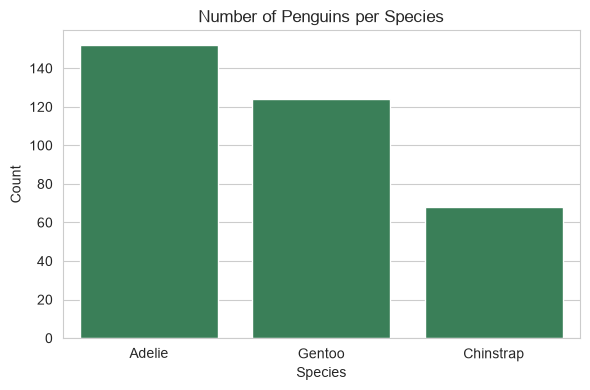

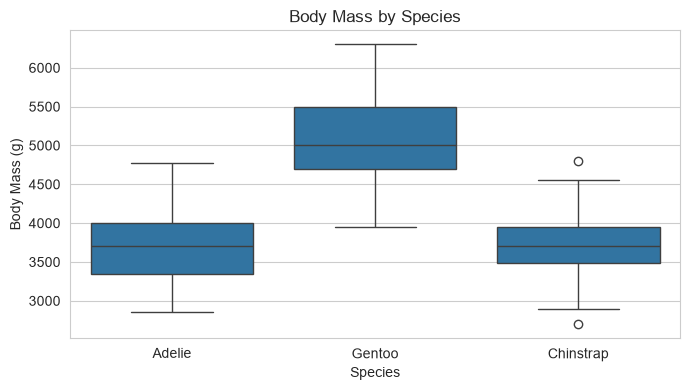

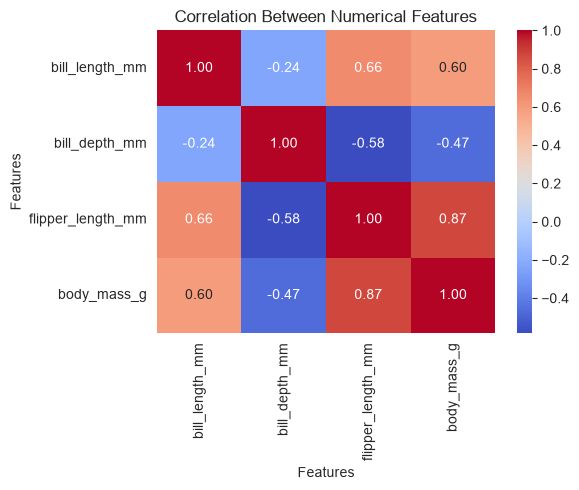

In [30]:
# Saving the Task 6 figures as PNG files for submission
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# Bar chart
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="species", order=df["species"].value_counts().index, color="seagreen")
plt.title("Number of Penguins per Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("bar_species.png", dpi=150)
plt.show()

# Boxplot
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="species", y="body_mass_g")
plt.title("Body Mass by Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")
plt.tight_layout()
plt.savefig("box_mass_species.png", dpi=150)
plt.show()

# Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.savefig("heatmap_corr.png", dpi=150)
plt.show()